<h2>Modelling: Future Price Volatility 1

In [1]:
import pandas as pd
import numpy as np

In [2]:
from project_paths import RAW_DATA_PATH
raw_data = pd.read_pickle(RAW_DATA_PATH)
raw_data.head()

Price,Date,Close,High,Low,Open,Volume
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


<h3>What is the best metric used to express the volatility label?</h3>

This will most likely be realised future volatility defined as:

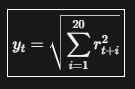

,where:

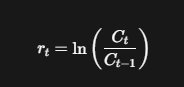

, which is daily log return. C_t is today's close, and C_t-1 is yesterday's close.

We can also add other volatility metrics which can act as features to help predict the label. These are:
- Daily log return (r_t)
- Absolute return (|r_t|)
- Squared return (r_t^2)
- Parkinson volatility (considers high and low prices of a price candle):

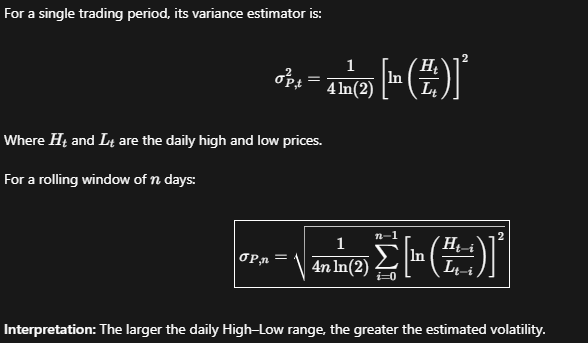

- Garman-Klass volatility (considers high, low, open and close prices of a candle):

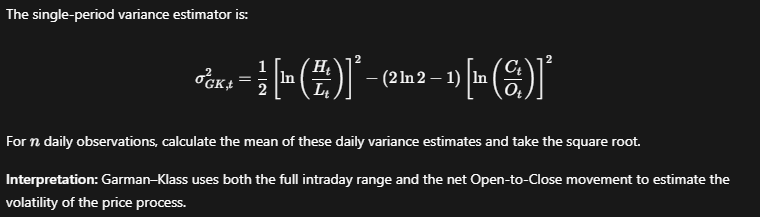 

- Realised historical volatility over 5, 10, 20, and 60 days looking into the past (rv_nd, similar to future volatility except it uses r_t-1 instead of r_t+1).
    - Using a range of time periods allow both short and long term volatility spikes to inform the model about volatility behaviour of the instrument.

In [3]:
H = 20 # Look-ahead period, 20 days in our case, the same as the direcion model.

# Create a copy of raw_data for manipulation:
df = raw_data.copy()

# Affirm that first observation is the oldest one, then drop the date column:
df = df.sort_values("Date", ascending=True).reset_index(drop=True)
df = df.drop(columns=["Date"])

# Daily returns
r = np.log(df["Close"] / df["Close"].shift(1))
r2 = r.pow(2)

# Historical features (past/current observations only)
df["log_return"] = r
df["abs_return"] = r.abs()
df["squared_return"] = r2

for window in [5, 10, 20, 60]:
    df[f"rv_{window}d"] = np.sqrt(
        r2.rolling(window).sum()
    )

# Range-based variance features
hl = np.log(df["High"] / df["Low"])
co = np.log(df["Close"] / df["Open"])

df["parkinson_var"] = hl**2 / (4 * np.log(2))
df["gk_var"] = 0.5 * hl**2 - (2 * np.log(2) - 1) * co**2

df["parkinson_vol_20d"] = np.sqrt(
    df["parkinson_var"].rolling(20).sum()
)

df["gk_vol_20d"] = np.sqrt(
    df["gk_var"].rolling(20).sum().clip(lower=0)
)

# Future 20-day volatility label
df["target_vol_20d"] = np.sqrt(
    r2.rolling(H).sum().shift(-H)
)

df.dropna(inplace=True)
df.head()

Price,Close,High,Low,Open,Volume,log_return,abs_return,squared_return,rv_5d,rv_10d,rv_20d,rv_60d,parkinson_var,gk_var,parkinson_vol_20d,gk_vol_20d,target_vol_20d
60,387.881989,390.799011,374.601990,374.730011,11905600,0.030758,0.030758,0.000946,0.165154,0.174279,0.197199,0.302961,0.000646,0.000436,0.171142,0.159725,0.097072
61,387.407990,410.199005,377.502014,388.348999,41518800,-0.001223,0.001223,0.000001,0.085271,0.173146,0.196772,0.293624,0.002489,0.003448,0.177839,0.169732,0.097068
62,375.197998,392.402008,371.117004,387.785004,32222500,-0.032024,0.032024,0.001026,0.090840,0.175856,0.188953,0.286354,0.001122,0.001135,0.176716,0.171248,0.098374
63,380.554993,386.480988,373.895996,373.895996,18931800,0.014177,0.014177,0.000201,0.072910,0.169142,0.187323,0.284547,0.000395,0.000428,0.175654,0.170274,0.101059
64,357.839996,382.024994,356.781006,380.307007,25233200,-0.061545,0.061545,0.003788,0.077213,0.179711,0.196113,0.290054,0.001686,0.000904,0.179373,0.171870,0.081891


In [4]:
# Reusable function to add volatility features to the OHLCV data.

def add_volatility_features(data: pd.DataFrame, horizon: int = 20, windows: tuple[int, ...] = (5, 10, 20, 60), range_window: int = 20) -> pd.DataFrame:
    """
    Build volatility features and the future realised volatility label from OHLCV data.

    Features use only past/current observations. The label is the realised
    volatility over the next `horizon` days (computed from future returns).

    Args:
        data: DataFrame with "Close", "High", "Low" and "Open" columns.
        horizon: Look-ahead period (days) for the target label.
        windows: Rolling windows (days) for historical realised volatility (rv_{n}d).
        range_window: Rolling window (days) for Parkinson and Garman-Klass volatility.

    Returns:
        New DataFrame (input is not modified) with added feature columns and
        `target_vol_{horizon}d`, with NaN rows removed.

    Example:
        >>> df = add_volatility_features(raw_data)
        >>> df = add_volatility_features(raw_data, horizon=10, windows=(5, 20))
    """
    df = data.copy()

    # Daily returns
    r = np.log(df["Close"] / df["Close"].shift(1))
    r2 = r ** 2

    # Historical features (past/current observations only)
    df["log_return"] = r
    df["abs_return"] = np.abs(r)
    df["squared_return"] = r2

    for w in windows:
        squared_returns = pd.Series(r2, index=df.index)
        df[f"rv_{w}d"] = np.sqrt(squared_returns.rolling(w).sum())

    # Range-based variance features
    hl = np.log(df["High"] / df["Low"])
    co = np.log(df["Close"] / df["Open"])

    df["parkinson_var"] = hl**2 / (4 * np.log(2))
    df["gk_var"] = 0.5 * hl**2 - (2 * np.log(2) - 1) * co**2

    df[f"parkinson_vol_{range_window}d"] = np.sqrt(df["parkinson_var"].rolling(range_window).sum())
    df[f"gk_vol_{range_window}d"] = np.sqrt(df["gk_var"].rolling(range_window).sum().clip(lower=0))

    # Future realised volatility label
    squared_returns = pd.Series(r2, index=df.index)
    df[f"target_vol_{horizon}d"] = np.sqrt(
        squared_returns.rolling(horizon).sum().shift(-horizon)
    )

    return df.dropna()

<h3>Data Preparation for Model Training:</h3>

- Raw data -> data + volatility features.
- Data splitting: Chronological 70/15/15 split.
- Pipeline:
    - Feature scaling: StandardScaler or RobustScaler, fitted on training data only.
    - Lookback (RollingWindowTransformer): 48 daily observations, like the direction model.
- LSTM input: (samples, 60, n_features), with validation + evaluation.

In [5]:
target = "target_vol_20d"

X = df.drop(columns=[target])
y = df[target]

split_idx = int(len(X) * 0.8)
val_idx = int(split_idx * 0.8)

X_train, X_val, X_test = X.iloc[:val_idx], X.iloc[val_idx:split_idx], X.iloc[split_idx:]
y_train, y_val, y_test = y.iloc[:val_idx], y.iloc[val_idx:split_idx], y.iloc[split_idx:]

print(f"Training samples: {len(X_train)} | Validation samples: {len(X_val)} | Test samples: {len(X_test)}")

Training samples: 2764 | Validation samples: 691 | Test samples: 864


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

# Custom lookback window feature transformer (same as the direction pipeline)
class RollingWindowTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, lookback=96):
        self.lookback = lookback

    def fit(self, X, y=None):
        X = np.asarray(X)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self)

        X = np.asarray(X, dtype=np.float32)

        if X.ndim != 2:
            raise ValueError("X must be 2D")

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Number of features has changed")

        if not 1 <= self.lookback <= len(X):
            raise ValueError("Invalid lookback")

        return np.stack([
            X[i:i + self.lookback]
            for i in range(len(X) - self.lookback + 1)
        ])

In [7]:
# Assemble the processing pipeline:

lookback = 48 # Same as the direction model

process_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("rolling", RollingWindowTransformer(lookback=lookback))
])

In [8]:
# Apply the pipeline

X_train_seq = process_pipeline.fit_transform(X_train)
X_val_seq = process_pipeline.transform(X_val)
X_test_seq = process_pipeline.transform(X_test)

print(X_train_seq.shape)
print(X_val_seq.shape)
print(X_test_seq.shape)

(2717, 48, 16)
(644, 48, 16)
(817, 48, 16)


In [9]:
# The rolling transformation reduces the number of samples by lookback - 1. Consequently, the target must be aligned with the end of each sequence:

y_train_seq = np.asarray(y_train)[lookback - 1:]
y_val_seq = np.asarray(y_val)[lookback - 1:]
y_test_seq = np.asarray(y_test)[lookback - 1:]

print(y_train_seq.shape)
print(y_val_seq.shape)
print(y_test_seq.shape)

(2717,)
(644,)
(817,)


In [10]:
# Shape lengths match nicely

In [11]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

In [31]:
# Next, create the LSTM. Simple starting configuration:

model = Sequential([
    # Input:
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),

    # Layer 1:
    LSTM(512, return_sequences=True),
    Dropout(0.5),

    # Layer 2:
    LSTM(256),
    Dropout(0.5),

    # Output:
    Dense(16, activation="relu"),
    Dense(1, activation="softplus") #If log volatility target, use linear. Here it isn't log.
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.Huber(),
    metrics=["mae"]
)

model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=15,
        min_lr=1e-6
    )
]

history = model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=150,
    batch_size=32,
    shuffle=True,
    callbacks=callbacks
)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_16 (LSTM)                  │ (None, 48, 512)        │     1,083,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 48, 512)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ (None, 256)            │       787,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 16)             │         4,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,874,977 (7.15 MB)

 Trainable params: 1,874,977 (7.15 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 14s 144ms/step - loss: 0.0226 - mae: 0.1414 - val_loss: 0.0019 - val_mae: 0.0532 - learning_rate: 1.0000e-04
Epoch 2/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 138ms/step - loss: 0.0032 - mae: 0.0584 - val_loss: 0.0034 - val_mae: 0.0737 - learning_rate: 1.0000e-04
Epoch 3/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 141ms/step - loss: 0.0029 - mae: 0.0555 - val_loss: 0.0014 - val_mae: 0.0450 - learning_rate: 1.0000e-04
Epoch 4/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 13s 150ms/step - loss: 0.0026 - mae: 0.0522 - val_loss: 0.0028 - val_mae: 0.0662 - learning_rate: 1.0000e-04
Epoch 5/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 144ms/step - loss: 0.0026 - mae: 0.0524 - val_loss: 0.0012 - val_mae: 0.0421 - learning_rate: 1.0000e-04
Epoch 6/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - loss: 0.0025 - mae: 0.0507 - val_loss: 0.0014 - val_mae: 0.0449 - learning_rate: 1.0000e-04
Epoch 7/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 142ms/step - loss: 0.0023 - mae: 0.0505 - val_loss: 0.0016 - val_mae:

Training Notes:
- For single layer architecture (1):
     (LSTM(n), Dropout(0.2), Dense(16, ReLu), Dense(1, Softplus)
     
     - Increaing n from 32, 64, 128, to 512 cause R2 to increase from -4 to 0.02, suggesting improvement, but then deteriorates for n = 512). Suggest that LSTM(256) is the optimal number of neurons for the first layer.
     - It can be quite tempramental between runs. Is this due to poor pattern recognition cause by model simplicity? It may also be caused by the propensity of the model to restore epoch 1 which always has the best val_loss when shuffle=False. shuffle=True is set to avoid this.
     - These were for LR = 1e-3. Training is quite unstable.

- For a multilayer architecture (2):
     (LSTM(n), Dropout(0.5), LSTM(m), Dropout(0.5), Dense(16, ReLu), Dense(1, Softplus)

     - Higher dropout due to overfitting risk.
     - shuffle=True is set to avoid the tempramental performance between training runs of the exact same model. Seems to allow restoration of later epochs rather than always restoring epoch 1 after training.
     - Tried LR = 1e-3. Quite unstable training. Moved to LR = 1e-4. Improves stability massively.
     - Going from n,m == (64,32), (128,64), (256,128) has little effect on performance. R2 hovers at around -2, with baseline R2 as -0.7. The training is much more stable by lowering LR.
     - Next may be to try lower LR but on single layer. Also need to try upping Dense(16) to Dense(32).

    

Evaluation:

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt

def evaluate_volatility(model: tf.keras.Model, X_test: np.ndarray, y_test: np.ndarray, baseline_vol: np.ndarray, history: tf.keras.callbacks.History | None = None) -> tuple[pd.DataFrame, np.ndarray, np.ndarray]:
    """
    Evaluate a volatility model against a persistence baseline, and optionally
    plot the training/validation loss curve and report the restored epoch.

    Args:
        model: Trained Keras model (predictions on the original volatility scale).
        X_test: Test sequences, shape (samples, lookback, n_features).
        y_test: True future volatility aligned with X_test.
        baseline_vol: Persistence forecast (e.g. test-set 'rv_20d', aligned with y_test).
        history: Optional History returned by `model.fit`. If given, plots the
            loss curves and prints the epoch whose weights were restored by
            EarlyStopping(restore_best_weights=True), i.e. the lowest val_loss epoch.

    Returns:
        (metrics DataFrame, y_true, y_pred)

    Example:
        >>> results, y_true, y_pred = evaluate_volatility(model, X_test_seq, y_test_seq, baseline_vol, history)
    """
    y_true = np.asarray(y_test).ravel()
    y_pred = model.predict(X_test, verbose=0).ravel()
    baseline = np.asarray(baseline_vol).ravel()

    if history is not None:
        train_loss, val_loss = history.history["loss"], history.history["val_loss"]
        best_epoch = int(np.argmin(val_loss)) + 1
        print(f"Restored weights from epoch {best_epoch} of {len(val_loss)} (val_loss={val_loss[best_epoch - 1]:.6f})")

        plt.figure(figsize=(8, 4))
        plt.plot(range(1, len(train_loss) + 1), train_loss, label="Train loss")
        plt.plot(range(1, len(val_loss) + 1), val_loss, label="Validation loss")
        plt.axvline(best_epoch, color="red", linestyle="--", label=f"Restored epoch ({best_epoch})")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training vs Validation Loss")
        plt.legend()
        plt.tight_layout()
        plt.show()

    def get_metrics(pred: np.ndarray) -> dict[str, float]:
        pred_var = np.maximum(pred**2, 1e-12)
        return {
            "MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "R2": r2_score(y_true, pred),
            "QLIKE": np.mean(np.log(pred_var) + y_true**2 / pred_var),
            "Correlation": np.corrcoef(y_true, pred)[0, 1]
        }

    results = pd.DataFrame({"LSTM": get_metrics(y_pred), "Persistence": get_metrics(baseline)}).T

    # float() resolves the type-checker error (Series / Scalar)
    persistence_mae = float(results.loc["Persistence", "MAE"])
    results["MAE Skill"] = 1 - results["MAE"] / persistence_mae

    return results, y_true, y_pred


Restored weights from epoch 10 of 25 (val_loss=0.000993)


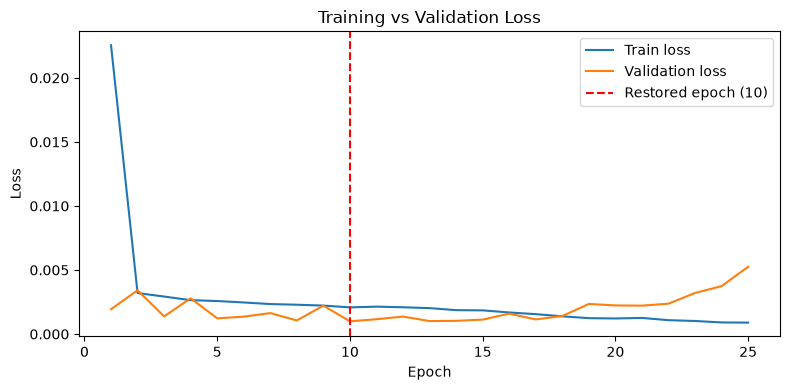

                  MAE      RMSE        R2     QLIKE  Correlation  MAE Skill
LSTM         0.061119  0.066847 -2.519006 -3.239334    -0.035751  -0.768391
Persistence  0.034562  0.046098 -0.673478 -3.211866     0.167571   0.000000


In [32]:
baseline_vol = X_test["rv_20d"].to_numpy()[lookback - 1:]
evaluation, y_true, y_pred = evaluate_volatility(model, X_test_seq, y_test_seq, baseline_vol,history)
print(evaluation)